<a href="https://colab.research.google.com/github/thogmartinl/nhanes-diabetes-screening/blob/main/nhanes_diabetes_screening.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Screening for Undiagnosed Elevated HbA1c (NHANES 2021-2023)

This notebook runs the complete pipeline for the Advanced Machine Learning final project. It predicts elevated HbA1c (5.7% or higher) in U.S. adults without diagnosed diabetes, using only information available without a blood test from NHANES August 2021-August 2023. It compares a random forest and a neural network with the ADA Diabetes Risk Test, the current questionnaire-based screening tool.

**How to run:** select *Runtime → Run all*. The notebook downloads the data from the CDC website and loads the trained models from the [GitHub repository](https://github.com/thogmartinl/nhanes-diabetes-screening), which also contains all functions in its `src` folder. To retrain the models instead (about 16 minutes), set `TRAIN_MODELS = True` in the setup cell.

## 0. Setup

Clones the GitHub repository with the source code and the trained models, imports the libraries, and sets a fixed random seed so that every run gives the same results. `TRAIN_MODELS` controls whether the models are retrained or loaded.

In [ ]:
# 0.1  Setup: clone the repository, import libraries, set the random seed and TRAIN_MODELS
# ----------------------------------------------------------------------------------------

import os
import sys
import pandas as pd
import matplotlib.pyplot as plt

# Clone the project repository from GitHub.
# If it is already cloned in this session, pull the latest version instead.

REPO_URL = "https://github.com/thogmartinl/nhanes-diabetes-screening.git"
REPO_DIR = "/content/nhanes-diabetes-screening"

if not os.path.exists(REPO_DIR):
    !git clone -q {REPO_URL} {REPO_DIR}
else:
    !git -C {REPO_DIR} pull -q

# Make the repository's src folder importable
sys.path.insert(0, REPO_DIR)

print(sorted(os.listdir(REPO_DIR)))

# Reload any src modules already imported, so edits pulled from GitHub take effect
import importlib
for name, module in list(sys.modules.items()):
    if name.startswith("src."):
        importlib.reload(module)

RANDOM_STATE = 42  # fixed seed so every run gives the same split and results

# True: retune both models (about 16 minutes) and save them.
# False: load the trained models from the GitHub repository (default).
TRAIN_MODELS = False

['.git', 'README.md', 'models', 'src']


## 1. Data download and loading

Downloads the 25 NHANES files directly from the CDC website (`src/data.py`) and merges them into one table with one row per participant, using the participant ID (SEQN).

In [ ]:
# 1.1  Download the 25 NHANES files from the CDC website
# ------------------------------------------------------

from src.data import download_all

DATA_DIR = download_all("/content/data")

Demographics   DEMO_L     skipped (already downloaded)
Examination    BMX_L      skipped (already downloaded)
Examination    BPXO_L     skipped (already downloaded)
Laboratory     GHB_L      skipped (already downloaded)
Laboratory     GLU_L      skipped (already downloaded)
Laboratory     HDL_L      skipped (already downloaded)
Laboratory     INS_L      skipped (already downloaded)
Laboratory     TCHOL_L    skipped (already downloaded)
Laboratory     TRIGLY_L   skipped (already downloaded)
Laboratory     FASTQX_L   skipped (already downloaded)
Questionnaire  ALQ_L      skipped (already downloaded)
Questionnaire  BPQ_L      skipped (already downloaded)
Questionnaire  DBQ_L      skipped (already downloaded)
Questionnaire  DIQ_L      skipped (already downloaded)
Questionnaire  DPQ_L      skipped (already downloaded)
Questionnaire  FNQ_L      skipped (already downloaded)
Questionnaire  HIQ_L      skipped (already downloaded)
Questionnaire  HUQ_L      skipped (already downloaded)
Questionna

In [ ]:
# 1.2  Load the files and merge them on SEQN (check: 11,933 participants, 265 columns)
# ------------------------------------------------------------------------------------

from src.data import load_all, merge_on_seqn

tables = load_all(DATA_DIR)
for name, df in tables.items():
    print(f"{name:10s} {df.shape[0]:6d} rows  {df.shape[1]:3d} cols")

data = merge_on_seqn(tables)
print("\nMerged:", data.shape)

# Check: the merge must reproduce the counts reported in the proposal
assert data.shape == (11933, 265), f"Unexpected shape: {data.shape}"
assert data["SEQN"].is_unique

DEMO_L      11933 rows   27 cols
BMX_L        8860 rows   22 cols
BPXO_L       7801 rows   12 cols
GHB_L        7199 rows    3 cols
GLU_L        3996 rows    4 cols
HDL_L        8068 rows    4 cols
INS_L        3996 rows    5 cols
TCHOL_L      8068 rows    4 cols
TRIGLY_L     3996 rows   10 cols
FASTQX_L     8727 rows   19 cols
ALQ_L        6337 rows    9 cols
BPQ_L        8501 rows    6 cols
DBQ_L       11933 rows   27 cols
DIQ_L       11744 rows    9 cols
DPQ_L        6337 rows   11 cols
FNQ_L       10942 rows   32 cols
HIQ_L       11933 rows   11 cols
HUQ_L       11933 rows    6 cols
INQ_L       11933 rows    5 cols
MCQ_L       11744 rows   35 cols
PAQ_L        8153 rows    8 cols
RXQ_RX_L    11933 rows    3 cols
SLQ_L        8501 rows    7 cols
SMQ_L        9015 rows    9 cols
WHQ_L        8501 rows    5 cols

Merged: (11933, 265)


## 2. Preprocessing

Selects the screening sample: adults with an HbA1c result and no diabetes diagnosis, excluding pregnant participants and participants taking diabetes pills. Then converts the special codes for "refused" and "don't know" to missing values and resolves the skip patterns (`src/preprocessing.py`).

In [ ]:
# 2.1  Select the screening sample (check: 5,182 before the new exclusions, 5,060 after)
# --------------------------------------------------------------------------------------

from src.preprocessing import select_screening_sample

screening, flow = select_screening_sample(data)
print(flow.to_string(index=False))
print("\nScreening sample:", screening.shape)

# Checks: the counts before the new exclusions must match the proposal
assert flow.loc[2, "Participants"] == 6002   # adults with HbA1c
assert flow.loc[3, "Participants"] == 5182   # screening sample in the proposal

                                              Step  Participants
                                  All participants         11933
                                  Aged 18 or older          8153
                              With an HbA1c result          6002
Excluded: reported diabetes diagnosis (DIQ010 = 1)          5182
         Excluded: pregnant at exam (RIDEXPRG = 1)          5145
      Excluded: taking diabetes pills (DIQ070 = 1)          5060

Screening sample: (5060, 265)


In [ ]:
# 2.2  Convert 'refused' and 'don't know' codes to missing values, per variable
# -----------------------------------------------------------------------------

from src.preprocessing import recode_missing, MISSING_CODES

clean = recode_missing(screening)

# How many values were recoded to missing, per variable
recoded = pd.Series({col: int(screening[col].isin(codes).sum())
                     for col, codes in MISSING_CODES.items()}, name="Recoded")
print(recoded.to_string())
print("\nTotal recoded:", recoded.sum())

# Check: no special codes remain
for col, codes in MISSING_CODES.items():
    assert not clean[col].isin(codes).any(), col

BPQ020      3
MCQ160B     3
MCQ160C    12
MCQ160D    10
MCQ160E     4
MCQ160F     5
SMQ020      6
SMQ040      0
PAD790Q    24
PAD800      8
PAD810Q    19
PAD820      8
ALQ111      2
ALQ121      4
ALQ130      9
DPQ010     12
DPQ020     10
DPQ030      5
DPQ040      6
DPQ050      2
DPQ060      4
DPQ070      2
DPQ080      7
DPQ090      1
HIQ011     12
HUQ010      2

Total recoded: 180


In [ ]:
# 2.3  Resolve skip patterns (smoking status, alcohol, physical activity)
# -----------------------------------------------------------------------

from src.preprocessing import resolve_skip_patterns

resolved = resolve_skip_patterns(clean)

print("Smoking status:")
print(resolved["smoking_status"].value_counts(dropna=False).to_string())

# How many blanks were filled by each rule
filled = pd.Series({
    "ALQ121 -> 0 (never drank)":            (clean["ALQ121"].isna() & resolved["ALQ121"].eq(0)).sum(),
    "ALQ130 -> 0 (no drinks in past year)": (clean["ALQ130"].isna() & resolved["ALQ130"].eq(0)).sum(),
    "PAD800 -> 0 (no moderate activity)":   (clean["PAD800"].isna() & resolved["PAD800"].eq(0)).sum(),
    "PAD820 -> 0 (no vigorous activity)":   (clean["PAD820"].isna() & resolved["PAD820"].eq(0)).sum(),
})
print("\nBlanks filled by skip patterns:")
print(filled.to_string())

Smoking status:
smoking_status
never      3135
former     1216
current     701
NaN           8

Blanks filled by skip patterns:
ALQ121 -> 0 (never drank)                417
ALQ130 -> 0 (no drinks in past year)    1023
PAD800 -> 0 (no moderate activity)       892
PAD820 -> 0 (no vigorous activity)      2550


## 3. Feature engineering

Creates the 19 model features (for example mean blood pressure, waist-to-height ratio, weekly physical activity, and the PHQ-9 score) and the target variable, elevated HbA1c (`src/features.py`).

In [ ]:
# 3.1  Build the 19 features and the target (elevated HbA1c, 5.7% or higher)
# --------------------------------------------------------------------------

from src.features import build_features, make_target, CVD_COLUMNS

X = build_features(resolved)
y = make_target(resolved)

print("Features:", X.shape)
print("Elevated HbA1c (>= 5.7%):", round(y.mean(), 3))
print("\nMissing values per feature:")
print(X.isna().sum().to_string())

# Check the claim in 4.1 that each cardiovascular condition affects few participants
print("\nCardiovascular conditions (Yes answers):")
print((resolved[CVD_COLUMNS] == 1).sum().to_string())

Features: (5060, 19)
Elevated HbA1c (>= 5.7%): 0.293

Missing values per feature:
age                     0
female                  0
race_ethnicity          0
income_ratio          645
bmi                    65
waist                 204
waist_height_ratio    209
systolic_bp           163
diastolic_bp          163
told_high_bp            3
cvd                   253
smoking_status          8
activity_log           60
alcohol_freq          642
alcohol_drinks        660
sleep_hours            46
phq9                  654
insured                12
health_rating           2

Cardiovascular conditions (Yes answers):
MCQ160B    133
MCQ160C    187
MCQ160D     85
MCQ160E    147
MCQ160F    168


## 4. Train/test split

Splits the data into a training set (80%) and a test set (20%), stratified by the target. Examines missing values in the training set and adds four missing indicators. Imputation and one-hot encoding happen inside each model pipeline and are fitted on training data only.

In [ ]:
# 4.1  Stratified 80/20 train/test split
# --------------------------------------

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Training set:", X_train.shape, "| elevated:", round(y_train.mean(), 3))
print("Test set:    ", X_test.shape, "| elevated:", round(y_test.mean(), 3))

Training set: (4048, 19) | elevated: 0.293
Test set:     (1012, 19) | elevated: 0.293


In [ ]:
# 4.2  Missing data diagnostic (training set only)
# ------------------------------------------------

missing = X_train.isna()

summary = pd.DataFrame({
    "Missing (n)": missing.sum(),
    "Missing (%)": (missing.mean() * 100).round(1),
    "Elevated if missing": [round(y_train[missing[c]].mean(), 3) if missing[c].any() else None
                            for c in X_train.columns],
    "Elevated if present": [round(y_train[~missing[c]].mean(), 3) for c in X_train.columns],
})
print(summary[summary["Missing (n)"] > 0].to_string())

# Are the same people missing alcohol and PHQ-9?
print("\nMissing alcohol frequency:", missing["alcohol_freq"].sum())
print("Missing PHQ-9:            ", missing["phq9"].sum())
print("Missing both:             ", (missing["alcohol_freq"] & missing["phq9"]).sum())

print("\nParticipants missing at least one feature:",
      missing.any(axis=1).sum(), "of", len(X_train))

                    Missing (n)  Missing (%)  Elevated if missing  Elevated if present
income_ratio                515         12.7                0.324                0.289
bmi                          54          1.3                0.241                0.294
waist                       167          4.1                0.281                0.294
waist_height_ratio          171          4.2                0.275                0.294
systolic_bp                 128          3.2                0.375                0.291
diastolic_bp                128          3.2                0.375                0.291
told_high_bp                  1          0.0                0.000                0.294
cvd                         207          5.1                0.058                0.306
smoking_status                4          0.1                0.250                0.294
activity_log                 56          1.4                0.268                0.294
alcohol_freq                500         12.

In [ ]:
# 4.3  Add missing indicators and check the imputation and encoding step
# ----------------------------------------------------------------------

from src.preprocessing import add_missing_indicators, make_preprocessor, CATEGORICAL

X_train = add_missing_indicators(X_train)
X_test = add_missing_indicators(X_test)
NUMERIC = [c for c in X_train.columns if c not in CATEGORICAL]

# Check: fit on the training data only and inspect the result
check = make_preprocessor(NUMERIC).fit(X_train)
X_train_ready = check.transform(X_train)
print("Features after imputation and one-hot encoding:", X_train_ready.shape[1])
print("Missing values left:", int(pd.isna(X_train_ready).sum()))
print("\nShare flagged by each indicator (training set):")
print(X_train[["income_missing", "alcohol_phq9_missing",
               "bp_missing", "cvd_missing"]].mean().round(3).to_string())

Features after imputation and one-hot encoding: 30
Missing values left: 0

Share flagged by each indicator (training set):
income_missing          0.127
alcohol_phq9_missing    0.129
bp_missing              0.032
cvd_missing             0.051


## 5. Exploratory analysis

Plots of the training set: the target, the first two hypotheses, the correlations between features, and the log transform of physical activity (`src/plots.py`). All figures are also saved to `/content/figures`.

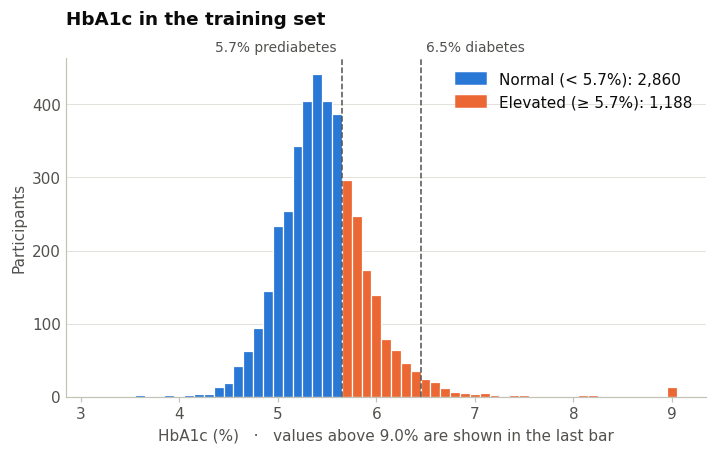

In [ ]:
# 5.1  Figure 1: HbA1c distribution
# ---------------------------------

from src.plots import set_style, save, plot_hba1c_distribution

set_style()

# HbA1c values for the training participants (same row labels as X_train)
hba1c_train = resolved.loc[X_train.index, "LBXGH"]

fig = plot_hba1c_distribution(hba1c_train)
save(fig, "01_hba1c_distribution")
plt.show()

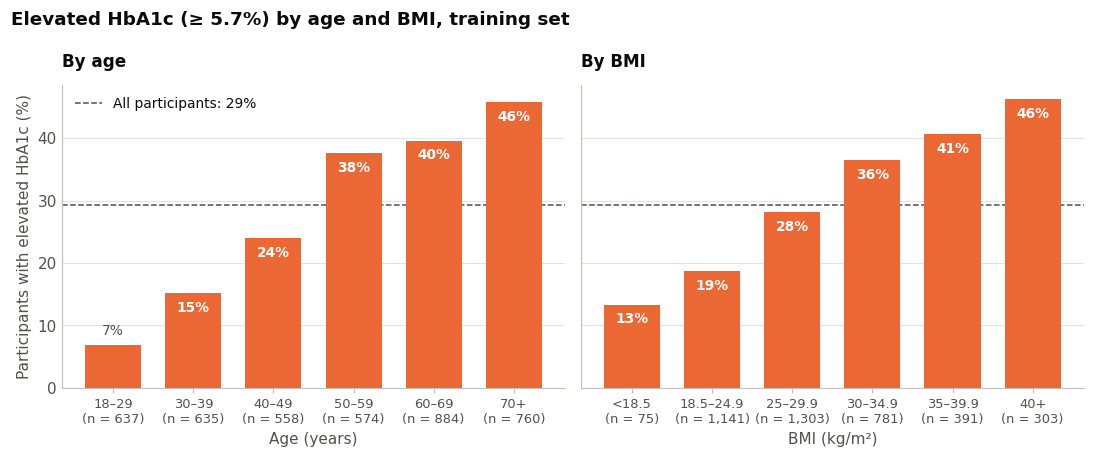

In [ ]:
# 5.2  Figure 2: elevated HbA1c by age group and BMI group (hypothesis 1)
# -----------------------------------------------------------------------

from src.plots import plot_elevated_by_group

fig = plot_elevated_by_group(X_train["age"], X_train["bmi"], y_train)
save(fig, "02_elevated_by_age_bmi")
plt.show()

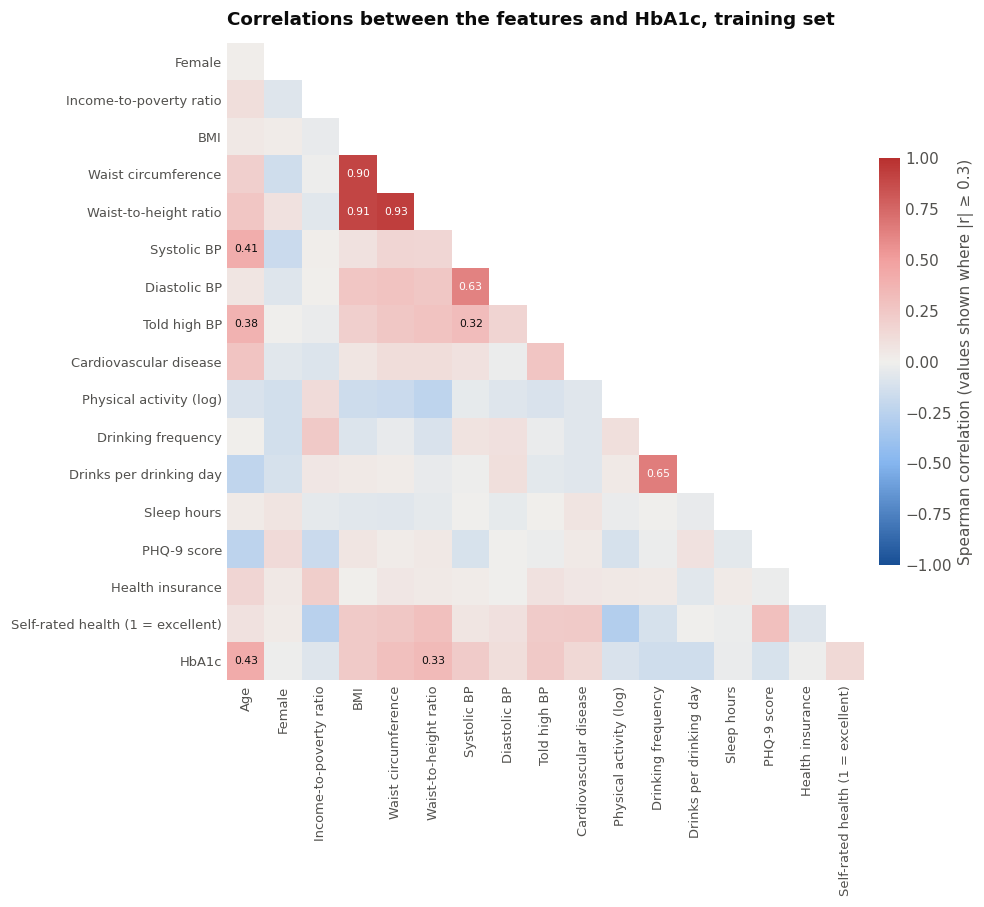

In [ ]:
# 5.3  Figure 3: correlations between the features and HbA1c
# ----------------------------------------------------------

from src.plots import plot_correlation_matrix, FEATURE_LABELS

# Numeric features in a fixed order (no categorical features, no missing indicators), plus HbA1c
corr_columns = [c for c in FEATURE_LABELS if c in X_train.columns]
corr_data = X_train[corr_columns].assign(hba1c=hba1c_train)

fig = plot_correlation_matrix(corr_data)
save(fig, "03_correlation_matrix")
plt.show()

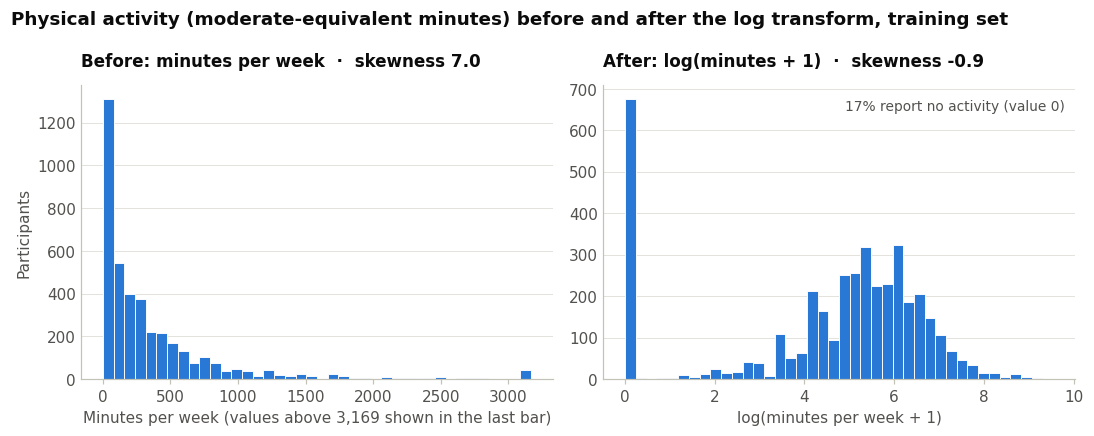

In [ ]:
# 5.4  Figure 4: physical activity before and after the log transform
# -------------------------------------------------------------------

from src.plots import plot_activity_transform

fig = plot_activity_transform(X_train["activity_log"])
save(fig, "04_activity_transform")
plt.show()

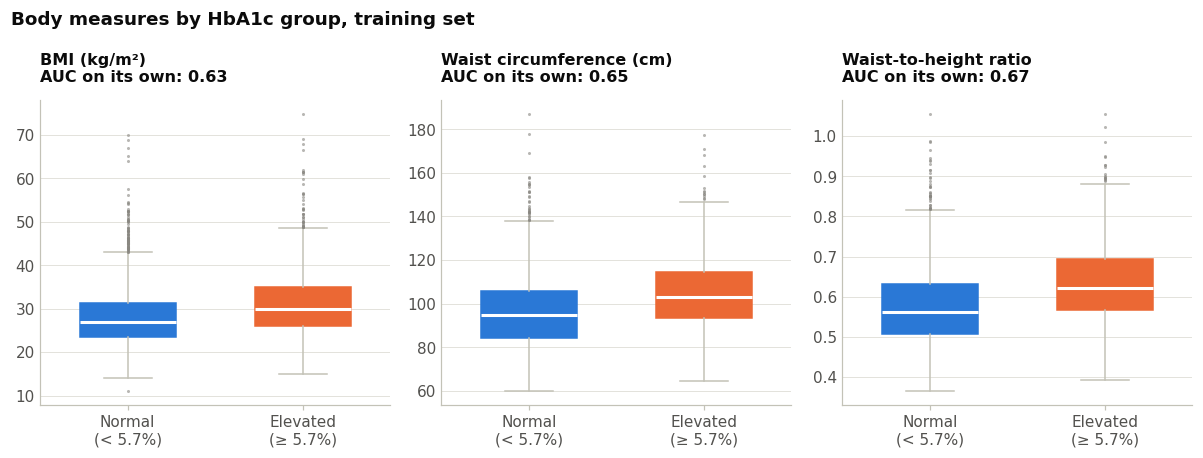

In [ ]:
# 5.5  Figure 5: body measures by HbA1c group (hypothesis 2)
# ----------------------------------------------------------

from src.plots import plot_body_measures

fig = plot_body_measures(X_train, y_train)
save(fig, "05_body_measures")
plt.show()

## 6. Model training

Tunes a random forest and a neural network with grid search and stratified 5-fold cross-validation on the training set (`src/models.py`). These cells only run if `TRAIN_MODELS = True`. Otherwise, the trained models are loaded in section 7.

In [ ]:
# 6.1  Random forest: grid search with 5-fold cross-validation (only if TRAIN_MODELS = True)
# ------------------------------------------------------------------------------------------

import time
from src.models import make_random_forest, RF_PARAM_GRID, tune

if TRAIN_MODELS:
    start = time.time()
    rf_search = tune(make_random_forest(NUMERIC, RANDOM_STATE), RF_PARAM_GRID,
                     X_train, y_train, RANDOM_STATE)
    print(f"Tuning took {time.time() - start:.0f} seconds\n")

    results = pd.DataFrame(rf_search.cv_results_)
    show = ["param_model__max_depth", "param_model__min_samples_leaf",
            "param_model__max_features", "mean_test_score", "std_test_score"]
    print(results.sort_values("rank_test_score")[show].head(5).round(3).to_string(index=False))

    print("\nBest settings:", rf_search.best_params_)
    print(f"Cross-validated ROC-AUC: {rf_search.best_score_:.3f}")
    rf_model = rf_search.best_estimator_
else:
    print("Skipped: TRAIN_MODELS is False, so the trained random forest is loaded in section 7.")

Skipped: TRAIN_MODELS is False, so the trained random forest is loaded in section 7.


In [ ]:
# 6.2  Neural network: grid search with 5-fold cross-validation (only if TRAIN_MODELS = True)
# -------------------------------------------------------------------------------------------

from src.models import make_neural_network, NN_PARAM_GRID

if TRAIN_MODELS:
    start = time.time()
    nn_search = tune(make_neural_network(NUMERIC, RANDOM_STATE), NN_PARAM_GRID,
                     X_train, y_train, RANDOM_STATE)
    print(f"Tuning took {time.time() - start:.0f} seconds\n")

    results = pd.DataFrame(nn_search.cv_results_)
    show = ["param_model__hidden_layer_sizes", "param_model__alpha",
            "param_model__learning_rate_init", "param_model__batch_size",
            "mean_test_score", "std_test_score"]
    print(results.sort_values("rank_test_score")[show].head(5).round(4).to_string(index=False))

    print("\nBest settings:", nn_search.best_params_)
    print(f"Cross-validated ROC-AUC: {nn_search.best_score_:.3f}")
    nn_model = nn_search.best_estimator_
else:
    print("Skipped: TRAIN_MODELS is False, so the trained neural network is loaded in section 7.")

Skipped: TRAIN_MODELS is False, so the trained neural network is loaded in section 7.


## 7. Loading trained parameters

Saves the trained models when retraining. Otherwise, loads the trained models, including their imputation, encoding, and scaling steps, from the repository's `models` folder for inference.

In [ ]:
# 7.1  Save the trained models (only if TRAIN_MODELS = True)
# ----------------------------------------------------------

from pathlib import Path
from src.models import save_model

if TRAIN_MODELS:
    OUT_DIR = Path("/content/trained_models")
    OUT_DIR.mkdir(exist_ok=True)
    save_model(rf_model, OUT_DIR / "random_forest.pkl",
               cv_roc_auc=rf_search.best_score_, best_params=rf_search.best_params_)
    save_model(nn_model, OUT_DIR / "neural_network.pkl",
               cv_roc_auc=nn_search.best_score_, best_params=nn_search.best_params_)
    print("Saved to /content/trained_models. Upload both files to the repository's models folder.")
else:
    print("Skipped: TRAIN_MODELS is False.")

Skipped: TRAIN_MODELS is False.


In [ ]:
# 7.2  Load the trained models from the repository for inference (always runs)
# ----------------------------------------------------------------------------

from src.models import load_model

MODEL_DIR = Path(REPO_DIR) / "models"
rf_saved = load_model(MODEL_DIR / "random_forest.pkl")
nn_saved = load_model(MODEL_DIR / "neural_network.pkl")
rf_model, nn_model = rf_saved["model"], nn_saved["model"]

for name, saved in [("Random forest", rf_saved), ("Neural network", nn_saved)]:
    print(f"{name}: trained with scikit-learn {saved['sklearn_version']}, "
          f"cross-validated ROC-AUC {saved['cv_roc_auc']:.3f}")
    print(f"  best settings: {saved['best_params']}")

Random forest: trained with scikit-learn 1.6.1, cross-validated ROC-AUC 0.763
  best settings: {'model__max_depth': 8, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5}
Neural network: trained with scikit-learn 1.6.1, cross-validated ROC-AUC 0.763
  best settings: {'model__alpha': 0.1, 'model__batch_size': 32, 'model__hidden_layer_sizes': (128,), 'model__learning_rate_init': 0.001}


## 8. ADA Diabetes Risk Test

Rebuilds the ADA Diabetes Risk Test from NHANES variables (`src/ada.py`). The score is a fixed point system and requires no training.

In [ ]:
# 8.1  Rebuild the ADA Diabetes Risk Test score from NHANES variables
# -------------------------------------------------------------------

from src.ada import ada_risk_score, ADA_CUTOFF

ada_train = ada_risk_score(X_train)
ada_test = ada_risk_score(X_test)      # used only in the final evaluation

# Missing answers that scored 0 points (training set)
print("Missing answers scored as 0 points (training set):")
print(X_train[["told_high_bp", "activity_log", "bmi"]].isna().sum().to_string())

# How often each item scores at least 1 point
print("\nShare of training participants scoring each item:")
print((ada_train.drop(columns="total") > 0).mean().round(3).to_string())

# Elevated HbA1c rate at each total score
by_score = pd.DataFrame({
    "Participants": ada_train["total"].value_counts().sort_index(),
    "Elevated HbA1c (%)": (y_train.groupby(ada_train["total"]).mean() * 100).round(1),
})
print("\nTraining set by total score:")
print(by_score.to_string())
print(f"\nHigh risk (score ≥ {ADA_CUTOFF}): "
      f"{(ada_train['total'] >= ADA_CUTOFF).mean():.1%} of training participants")

Missing answers scored as 0 points (training set):
told_high_bp     1
activity_log    56
bmi             54

Share of training participants scoring each item:
age         0.686
male        0.447
high_bp     0.311
inactive    0.167
weight      0.686

Training set by total score:
       Participants  Elevated HbA1c (%)
total                                  
0               223                 2.7
1               428                 5.8
2               534                13.5
3               693                22.8
4               696                33.6
5               667                42.1
6               487                47.6
7               249                55.4
8                64                57.8
9                 7                71.4

High risk (score ≥ 5): 36.4% of training participants


## 9. Evaluation

Compares the random forest, the neural network, and the ADA risk score on the test set, which is used here for the first time (`src/evaluation.py`). Covers discrimination, screening performance, calibration, the three hypotheses, and performance across subgroups.

### Discrimination and screening performance

In [ ]:
# 9.1  Discrimination on the test set: ROC-AUC and PR-AUC with bootstrap confidence intervals
# -------------------------------------------------------------------------------------------

from src.evaluation import bootstrap_discrimination

# Predicted risk on the test set (the test set is used here for the first time)
test_scores = {
    "Random forest": rf_model.predict_proba(X_test)[:, 1],
    "Neural network": nn_model.predict_proba(X_test)[:, 1],
    "ADA risk score": ada_test["total"].values,
}

discrimination = bootstrap_discrimination(y_test, test_scores, reference="ADA risk score",
                                          random_state=RANDOM_STATE)
pd.set_option("display.width", 200)
print(discrimination.to_string())
print(f"\nShare with elevated HbA1c in the test set (PR-AUC of a random guess): {y_test.mean():.3f}")

                      ROC-AUC (95% CI)         PR-AUC (95% CI) ROC-AUC difference vs. ADA risk score (95% CI)
Model                                                                                                        
Random forest   0.774 (0.743 to 0.804)  0.557 (0.500 to 0.618)                         0.045 (0.024 to 0.066)
Neural network  0.763 (0.730 to 0.794)  0.533 (0.477 to 0.595)                         0.034 (0.011 to 0.058)
ADA risk score  0.729 (0.697 to 0.760)  0.470 (0.420 to 0.526)                                      reference

Share with elevated HbA1c in the test set (PR-AUC of a random guess): 0.293


In [ ]:
# 9.2  Screening performance at thresholds chosen on the training set
# -------------------------------------------------------------------

from src.evaluation import oof_predictions, threshold_for_sensitivity, screening_metrics

# Thresholds chosen on the training set only
oof = {"Random forest": oof_predictions(rf_model, X_train, y_train, RANDOM_STATE),
       "Neural network": oof_predictions(nn_model, X_train, y_train, RANDOM_STATE)}
thresholds = {name: threshold_for_sensitivity(y_train, p) for name, p in oof.items()}
ada_80 = threshold_for_sensitivity(y_train, ada_train["total"])

# Applied unchanged to the test set
screening = pd.DataFrame({
    "Random forest": screening_metrics(y_test, test_scores["Random forest"], thresholds["Random forest"]),
    "Neural network": screening_metrics(y_test, test_scores["Neural network"], thresholds["Neural network"]),
    f"ADA risk score (official cut-off {ADA_CUTOFF})": screening_metrics(y_test, test_scores["ADA risk score"], ADA_CUTOFF),
    "ADA risk score (≥ 80% sensitivity)": screening_metrics(y_test, test_scores["ADA risk score"], ada_80),
}).T
print(screening.to_string())

                                    Threshold Sensitivity Specificity Precision (PPV)    NPV Accuracy Flagged (%) Found / missed
Random forest                           0.283       0.778       0.635            0.47  0.873    0.677        48.6       231 / 66
Neural network                          0.259       0.795       0.622           0.466  0.879    0.673        50.0       236 / 61
ADA risk score (official cut-off 5)       5.0       0.586       0.743           0.486  0.812    0.697        35.4      174 / 123
ADA risk score (≥ 80% sensitivity)        3.0       0.892       0.404           0.384    0.9    0.547        68.3       265 / 32


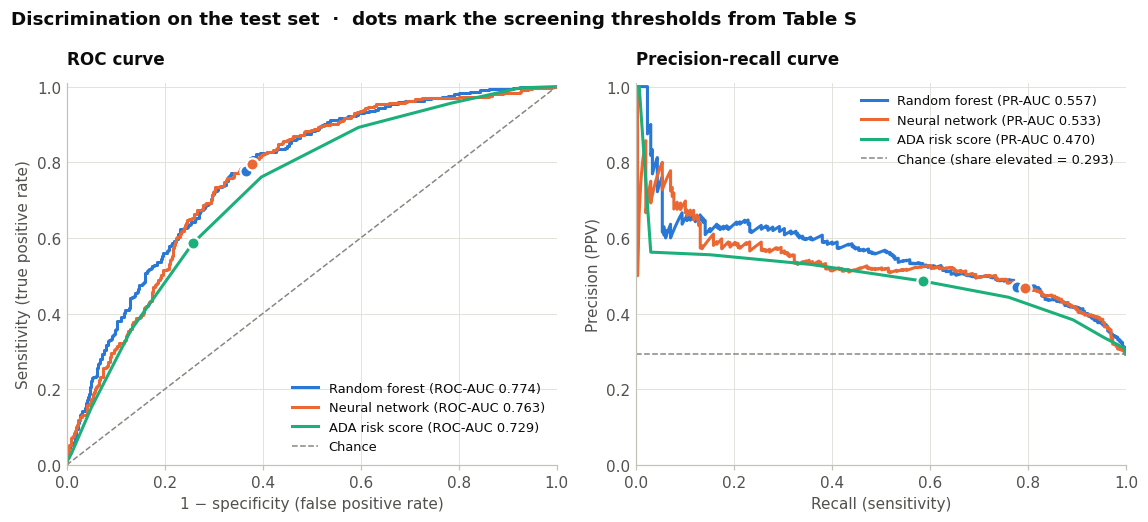

In [ ]:
# 9.3  Figure 6: ROC and precision-recall curves
# ----------------------------------------------

from src.plots import plot_roc_pr

operating_points = {"Random forest": thresholds["Random forest"],
                    "Neural network": thresholds["Neural network"],
                    "ADA risk score": ADA_CUTOFF}

fig = plot_roc_pr(y_test, test_scores, operating_points)
save(fig, "06_roc_pr_curves")
plt.show()

### Calibration

                                        Brier score  Brier skill score  Mean predicted risk  Observed rate  Calibration slope
Model                                                                                                                        
Random forest                                 0.169              0.183                0.289          0.293               1.28
Neural network                                0.172              0.172                0.284          0.293               0.95
Reference (predict 0.293 for everyone)        0.207              0.000                0.293          0.293                NaN


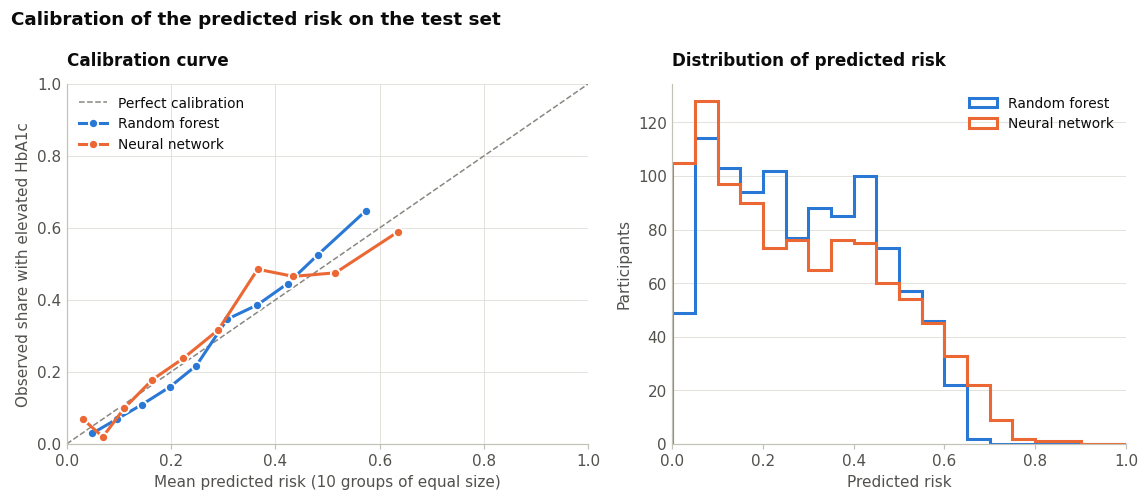

In [ ]:
# 9.4  Calibration: Brier score, calibration slope, and Figure 7
# --------------------------------------------------------------

from src.evaluation import calibration_summary
from src.plots import plot_calibration

model_probs = {"Random forest": test_scores["Random forest"],
               "Neural network": test_scores["Neural network"]}

print(calibration_summary(y_test, model_probs, reference_rate=y_train.mean()).to_string())

fig = plot_calibration(y_test, model_probs)
save(fig, "07_calibration")
plt.show()

### Hypothesis tests

                                         Random forest  Neural network
Feature group                                                         
Age                                             0.1009          0.0885
Body size (BMI, waist, waist-to-height)         0.0603          0.0479
Race/ethnicity                                  0.0176          0.0209
Blood pressure                                  0.0143          0.0077
Alcohol                                         0.0052          0.0076
Income-to-poverty ratio                         0.0029          0.0004
Physical activity                               0.0020          0.0004
Smoking                                         0.0007          0.0014
Cardiovascular disease                          0.0007          0.0025
Self-rated health                               0.0006          0.0003
Sex                                             0.0004          0.0031
Sleep                                           0.0003          0.0011
Health

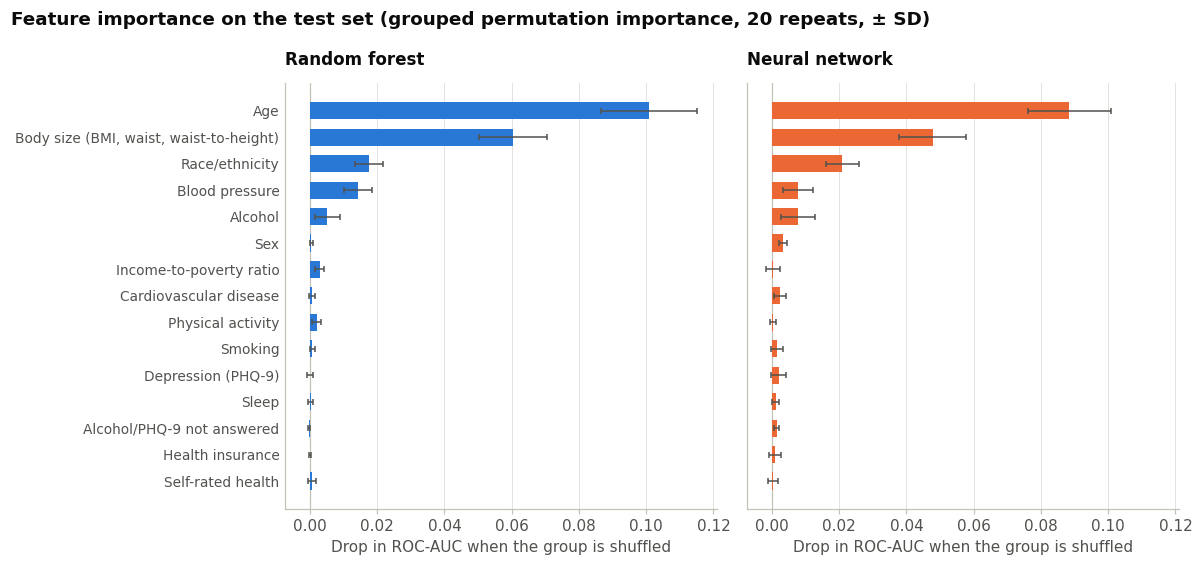

In [ ]:
# 9.5  Hypothesis 1: grouped permutation importance (Figure 8)
# ------------------------------------------------------------

from src.evaluation import grouped_permutation_importance
from src.plots import plot_feature_importance

importances = {
    "Random forest": grouped_permutation_importance(rf_model, X_test, y_test, random_state=RANDOM_STATE),
    "Neural network": grouped_permutation_importance(nn_model, X_test, y_test, random_state=RANDOM_STATE),
}

summary = pd.concat({name: t["Mean drop in ROC-AUC"] for name, t in importances.items()}, axis=1)
print(summary.sort_values("Random forest", ascending=False).round(4).to_string())

fig = plot_feature_importance(importances)
save(fig, "08_feature_importance")
plt.show()

In [ ]:
# 9.6  Hypothesis 2: BMI vs. waist measures (cross-validation on the training set)
# --------------------------------------------------------------------------------

from src.evaluation import cv_auc_by_feature_set
from src.models import make_random_forest, make_neural_network

BODY = ["bmi", "waist", "waist_height_ratio"]
ALL = list(X_train.columns)
no_body = [c for c in ALL if c not in BODY]
h2_sets = {
    "No body measure": no_body,
    "BMI only": no_body + ["bmi"],
    "Waist only": no_body + ["waist"],
    "Waist-to-height ratio only": no_body + ["waist_height_ratio"],
    "All three (full model)": ALL,
}

for name, make_model, saved in [("Random forest", make_random_forest, rf_saved),
                                ("Neural network", make_neural_network, nn_saved)]:
    print(f"\n{name}")
    print(cv_auc_by_feature_set(make_model, saved["best_params"], X_train, y_train,
                                h2_sets, reference="BMI only",
                                random_state=RANDOM_STATE).to_string())


Random forest
                            Features  CV ROC-AUC     SD  Difference vs. BMI only  SD of difference
Feature set                                                                                       
No body measure                   20       0.750  0.015                   -0.011             0.010
BMI only                          21       0.761  0.019                    0.000             0.000
Waist only                        21       0.764  0.021                    0.003             0.006
Waist-to-height ratio only        21       0.766  0.020                    0.006             0.002
All three (full model)            23       0.763  0.024                    0.003             0.005

Neural network
                            Features  CV ROC-AUC     SD  Difference vs. BMI only  SD of difference
Feature set                                                                                       
No body measure                   20       0.742  0.021                   -0.0

In [ ]:
# 9.7  Hypothesis 3: feature groups added step by step (cross-validation on the training set)
# -------------------------------------------------------------------------------------------

step1 = ["age", "bmi", "waist", "waist_height_ratio"]
step2 = step1 + ["systolic_bp", "diastolic_bp", "told_high_bp", "bp_missing", "cvd", "cvd_missing"]
step3 = step2 + ["smoking_status", "activity_log", "alcohol_freq", "alcohol_drinks",
                 "sleep_hours", "alcohol_phq9_missing"]
h3_sets = {
    "1. Age + body size": step1,
    "2. + Blood pressure and cardiovascular disease": step2,
    "3. + Lifestyle": step3,
    "4. Full model": ALL,
}

for name, make_model, saved in [("Random forest", make_random_forest, rf_saved),
                                ("Neural network", make_neural_network, nn_saved)]:
    print(f"\n{name}")
    print(cv_auc_by_feature_set(make_model, saved["best_params"], X_train, y_train,
                                h3_sets, reference="1. Age + body size",
                                random_state=RANDOM_STATE).to_string())


Random forest
                                                Features  CV ROC-AUC     SD  Difference vs. 1. Age + body size  SD of difference
Feature set                                                                                                                     
1. Age + body size                                     4       0.724  0.021                              0.000             0.000
2. + Blood pressure and cardiovascular disease        10       0.732  0.023                              0.008             0.005
3. + Lifestyle                                        16       0.750  0.025                              0.026             0.007
4. Full model                                         23       0.763  0.024                              0.039             0.006

Neural network
                                                Features  CV ROC-AUC     SD  Difference vs. 1. Age + body size  SD of difference
Feature set                                                       

### Diabetes range and subgroups

In [ ]:
# 9.8  Diabetes range (HbA1c 6.5% or higher) and performance by subgroup
# ----------------------------------------------------------------------

import numpy as np
from src.evaluation import subgroup_performance

# Part 1: diabetes range (HbA1c >= 6.5%) in the test set
hba1c_test = resolved.loc[X_test.index, "LBXGH"]
in_diabetes_range = (hba1c_test >= 6.5).to_numpy()
print(f"Test participants in the diabetes range: {in_diabetes_range.sum()}\n")

rules = {"Random forest": ("Random forest", thresholds["Random forest"]),
         "Neural network": ("Neural network", thresholds["Neural network"]),
         f"ADA risk score (cut-off {ADA_CUTOFF})": ("ADA risk score", ADA_CUTOFF),
         "ADA risk score (cut-off 3)": ("ADA risk score", ada_80)}
for label, (name, threshold) in rules.items():
    flagged = np.asarray(test_scores[name])[in_diabetes_range] >= threshold
    print(f"{label:30s} flags {flagged.sum():3d} of {in_diabetes_range.sum()} ({flagged.mean():.0%})")

# Part 2: subgroups by gender and age
subgroups = {
    "Men": X_test["female"].eq(0),
    "Women": X_test["female"].eq(1),
    "Age 18-39": X_test["age"].lt(40),
    "Age 40-59": X_test["age"].between(40, 59),
    "Age 60+": X_test["age"].ge(60),
}
print("\n" + subgroup_performance(y_test, test_scores, operating_points, subgroups).to_string())

Test participants in the diabetes range: 20

Random forest                  flags  19 of 20 (95%)
Neural network                 flags  20 of 20 (100%)
ADA risk score (cut-off 5)     flags  13 of 20 (65%)
ADA risk score (cut-off 3)     flags  19 of 20 (95%)

             n  Elevated (%)  Random forest ROC-AUC  Random forest sensitivity  Neural network ROC-AUC  Neural network sensitivity  ADA risk score ROC-AUC  ADA risk score sensitivity
Subgroup                                                                                                                                                                              
Men        458          31.0                  0.736                      0.768                   0.721                       0.768                   0.698                       0.690
Women      554          28.0                  0.807                      0.787                   0.798                       0.819                   0.760                       0.490
Age 18-39